# Лабораторная работа №1
## «Анализ и прогнозирование временных рядов на примере розничных продаж»

**Выполнил(а):** Злобин Владимир Олегович \
**Группа:** М8О-202СВ-25 \
**Дисциплина:** Предиктивная аналитика

---
**Цель работы:** Провести разведочный анализ временного ряда, выполнить декомпозицию различными методами и построить прогнозные модели ARIMA/SARIMAX с оценкой их качества.

In [ ]:
%pip install pandas numpy matplotlib statsmodels scipy PyWavelets scikit-learn

## 2.1. Разведочный анализ данных (EDA)

### Настройка окружения и загрузка данных
В этой ячейке мы импортируем библиотеки и подготовим временной ряд для работы.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.fft import fft, fftfreq
import pywt

# Настройка стиля графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Загрузка данных
df = pd.read_csv('data/LW1/retail_sales_mock_data.csv', parse_dates=['Date'], index_col='Date')

# Выведем первые 5 строк для проверки
display(df.head())

,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


### Разведочный анализ данных
Визуализируем исходный ряд розничных продаж, чтобы оценить наличие тренда, сезонности и влияние промо-акций.

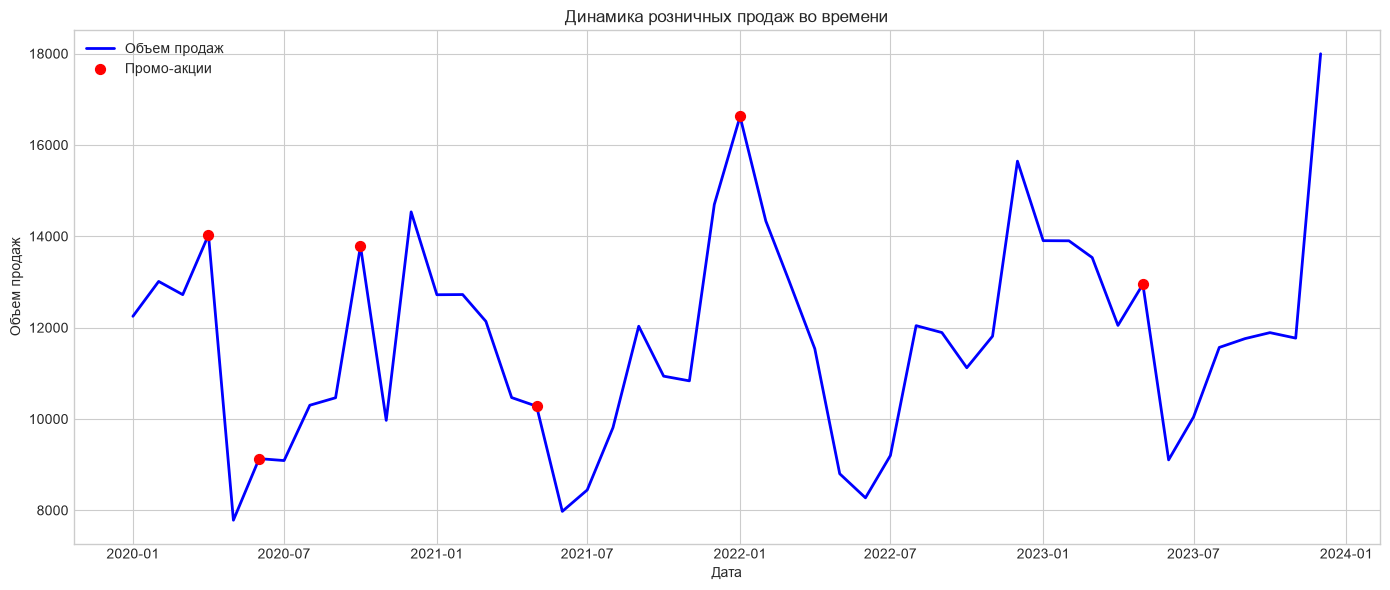

In [21]:
# Разведочный анализ (EDA)
plt.figure(figsize=(14, 6))

# Строим линейный график продаж
plt.plot(df.index, df['SalesAmount'], label='Объем продаж', color='blue', linewidth=2)

# Отметим точки, где проводились промо-акции (Promotion == 1)
promo_dates = df[df['Promotion'] == 1].index
promo_sales = df[df['Promotion'] == 1]['SalesAmount']
plt.scatter(promo_dates, promo_sales, color='red', s=50, zorder=5, label='Промо-акции')

plt.title('Динамика розничных продаж во времени')
plt.xlabel('Дата')
plt.ylabel('Объем продаж')
plt.legend()
plt.tight_layout()
plt.show()

### Классическая декомпозиция
Выполним разбиение ряда на тренд, сезонность и остатки с помощью seasonal_decompose. \
Поскольку у нас помесячные данные, логично предположить годовую сезонность (период = 12).

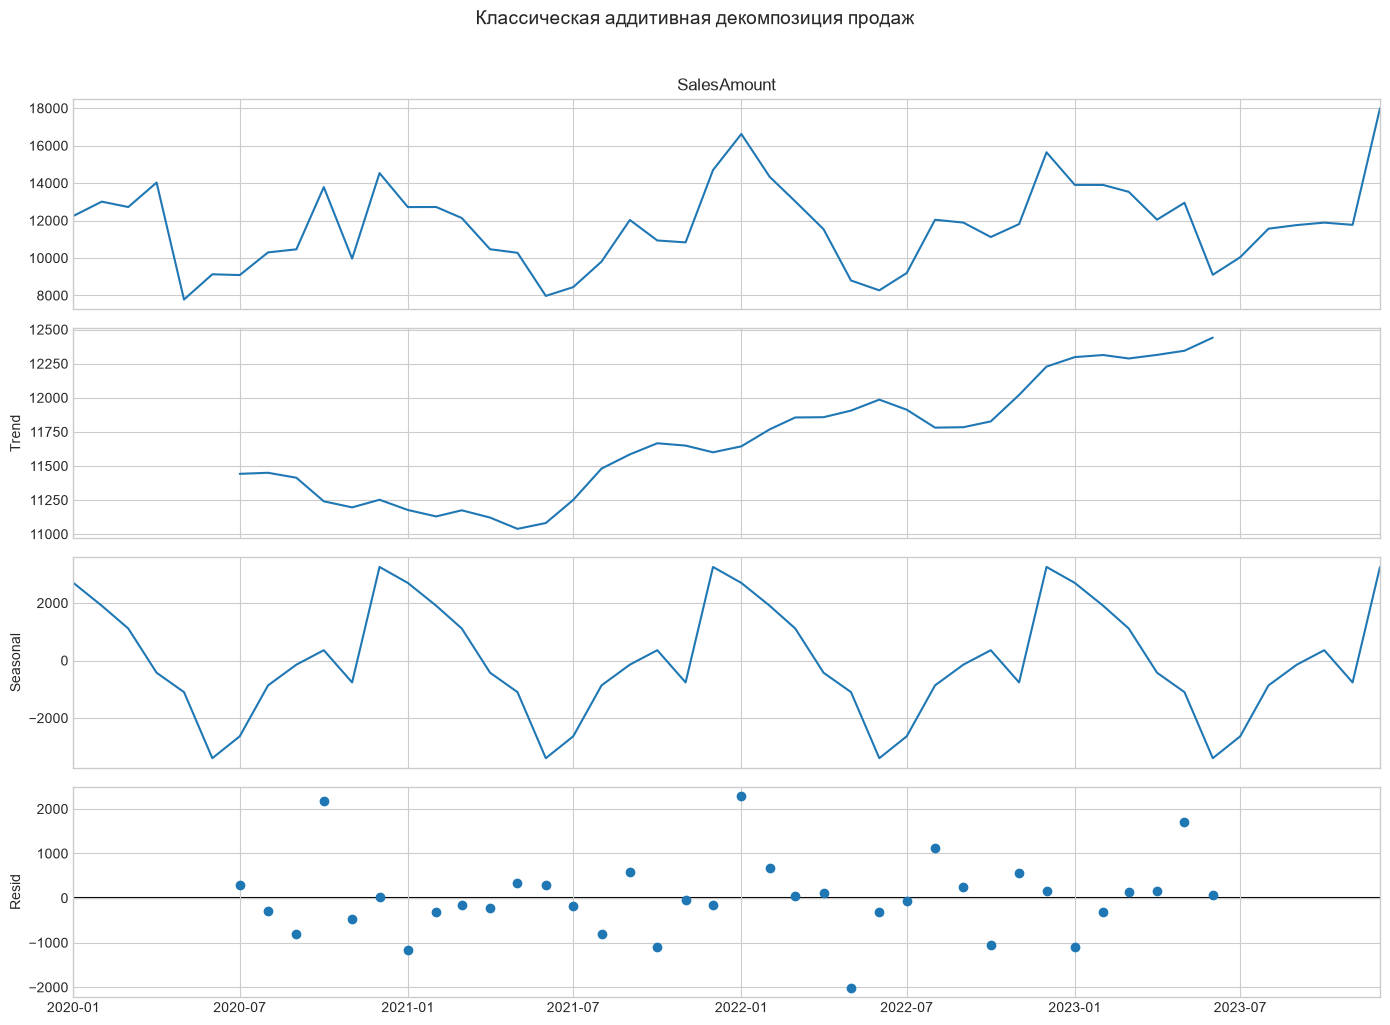

In [22]:
# Классическая декомпозиция
decomposition = seasonal_decompose(df['SalesAmount'], model='additive', period=12)

# Визуализация компонентов
fig = decomposition.plot()
fig.set_size_inches(14, 10)
fig.suptitle('Классическая аддитивная декомпозиция продаж', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Спектральный анализ (FFT)
Применим быстрое преобразование Фурье, чтобы найти скрытые цикличности (периоды) в данных.

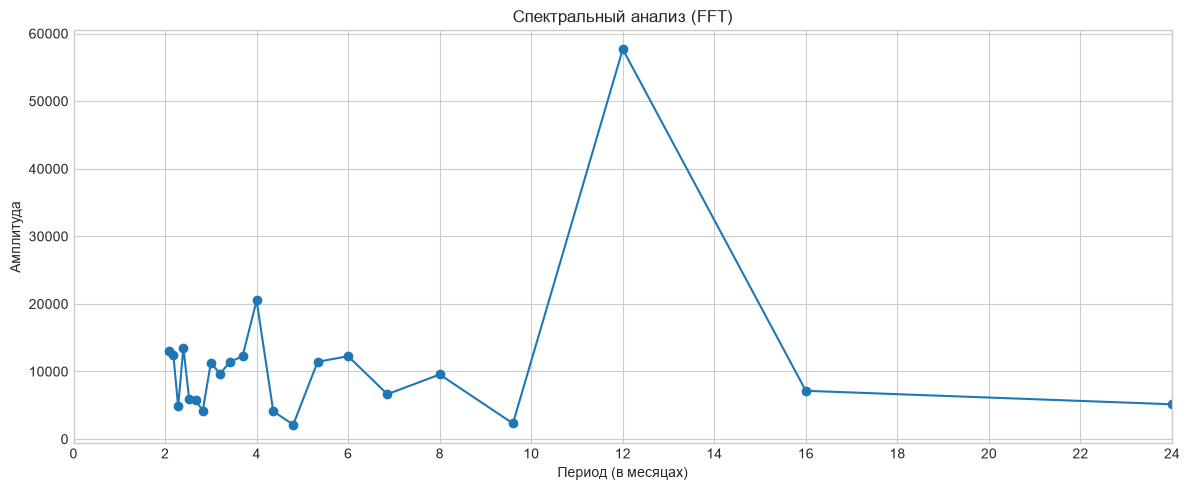

In [23]:
# Спектральный анализ с применением FFT
# Центрируем данные (вычитаем среднее) для удаления нулевой частоты (постоянной составляющей)
sales_centered = df['SalesAmount'] - df['SalesAmount'].mean()
n = len(sales_centered)

# Вычисляем FFT
yf = fft(sales_centered.values)
# Вычисляем частоты (в циклах за месяц, так как данные помесячные)
xf = fftfreq(n, d=1)

# Берем только положительные частоты (первая половина спектра)
xf_pos = xf[1:n//2]
yf_pos = np.abs(yf[1:n//2])

plt.figure(figsize=(12, 5))
plt.plot(1 / xf_pos, yf_pos, marker='o', linestyle='-') # Ось X переводим из частоты в период (месяцы)
plt.title('Спектральный анализ (FFT)')
plt.xlabel('Период (в месяцах)')
plt.ylabel('Амплитуда')
# Ограничим ось X для наглядности (до 24 месяцев)
plt.xlim(0, 24)
plt.xticks(np.arange(0, 25, 2))
plt.tight_layout()
plt.show()

### Вейвлет-анализ
Используем непрерывное вейвлет-преобразование (CWT) с вейвлетом Морле, чтобы посмотреть, как меняются частоты с течением времени.

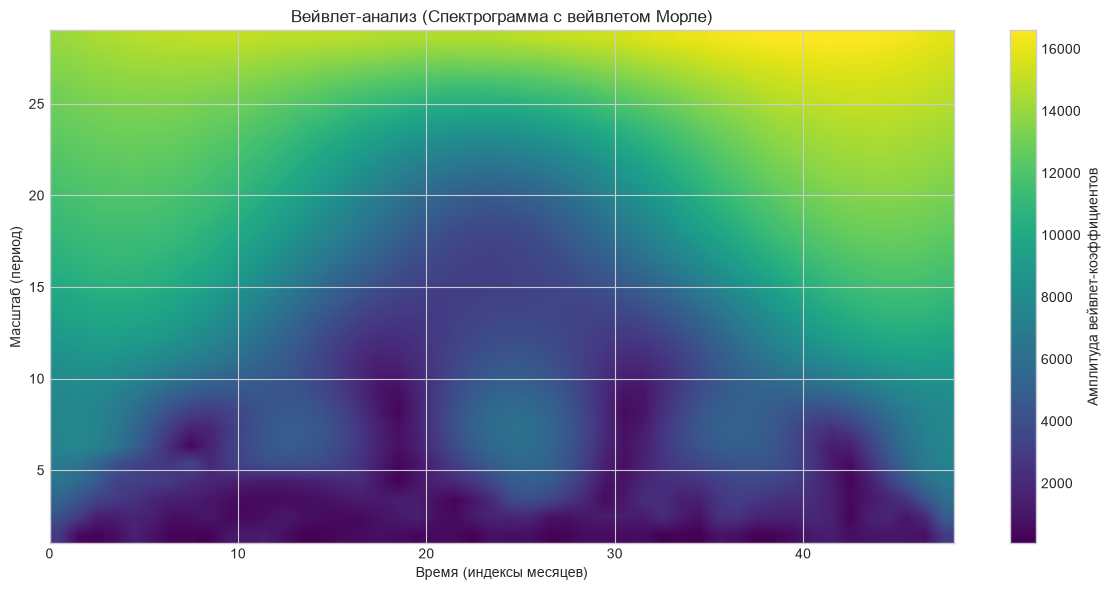

In [24]:
# Вейвлет-анализ (Вейвлет Морле)
# Задаем масштабы (scales), которые определяют анализируемые частоты
scales = np.arange(1, 30)
# Применяем непрерывное вейвлет-преобразование с вейвлетом Морле ('cmor')
coefficients, frequencies = pywt.cwt(df['SalesAmount'].values, scales, 'cmor1.0-0.5')

plt.figure(figsize=(12, 6))
# Визуализируем модуль коэффициентов (мощность сигнала)
plt.imshow(np.abs(coefficients), extent=[0, n, scales[-1], scales[0]],
           cmap='viridis', aspect='auto', interpolation='bilinear')
plt.colorbar(label='Амплитуда вейвлет-коэффициентов')
plt.title('Вейвлет-анализ (Спектрограмма с вейвлетом Морле)')
plt.ylabel('Масштаб (период)')
plt.xlabel('Время (индексы месяцев)')
plt.gca().invert_yaxis() # Переворачиваем ось Y для удобства (чтобы малые масштабы были сверху)
plt.tight_layout()
plt.show()

### Аналитические выводы по этапу 2.1: Разведочный анализ и декомпозиция
*   **Разведочный анализ (EDA):** На графике динамики продаж наблюдается нелинейный тренд с заметным проседанием в середине 2021 года и последующим ростом в 2022-2023 годах. Точки проведения промо-акций практически всегда совпадают с выраженными локальными максимумами, что подтверждает высокую значимость признака `Promotion` — он напрямую стимулирует скачки продаж.
*   **Классическая декомпозиция:** Метод `seasonal_decompose` успешно выделил устойчивую годовую сезонность (период 12 месяцев) с амплитудой колебаний около $\pm 3000$ единиц. Компонента тренда очищена от шума и наглядно подтверждает спад 2021 года с последующим восстановлением.
*   **Спектральный анализ (FFT):** Преобразование Фурье выявило абсолютно доминирующий пик амплитуды (около 60000) строго на периоде 12 месяцев. Это математически доказывает наличие сильного годового цикла в продажах. Также присутствует вторичный, менее выраженный пик на периоде 4 месяца, что может указывать на локальные квартальные колебания.
*   **Вейвлет-анализ:** Спектрограмма показывает распределение мощности сигнала во времени. Наибольшая амплитуда (желтая зона) сосредоточена на крупных масштабах (25+ месяцев), что отражает влияние сильного макро-тренда. В зоне масштаба 12 месяцев наблюдается равномерная полоса повышенной интенсивности на протяжении всего графика, что говорит о стабильности годовой сезонности — она присутствует постоянно, не затухает и не смещается во времени.

## 2.2. Построение прогнозных моделей

Поскольку на этапе EDA мы выявили тренд, ряд предположительно нестационарен — значит, нам понадобится дифференцирование (параметр `d=1`). \
Сезонность равна 12 месяцам, что пойдет в параметр `s` для SARIMAX. Последние 12 месяцев датасета мы отложим в тестовую выборку, чтобы потом оценить качество.

### Разделение данных и проверка на стационарность
Мы проведем тест Дики-Фуллера и построим графики автокорреляции (ACF и PACF), чтобы подтвердить наши гипотезы о параметрах.

Размер обучающей выборки (train): 36
Размер тестовой выборки (test): 12

--- Тест Дики-Фуллера (исходный ряд) ---
ADF Statistic: -3.7700
p-value: 0.0032


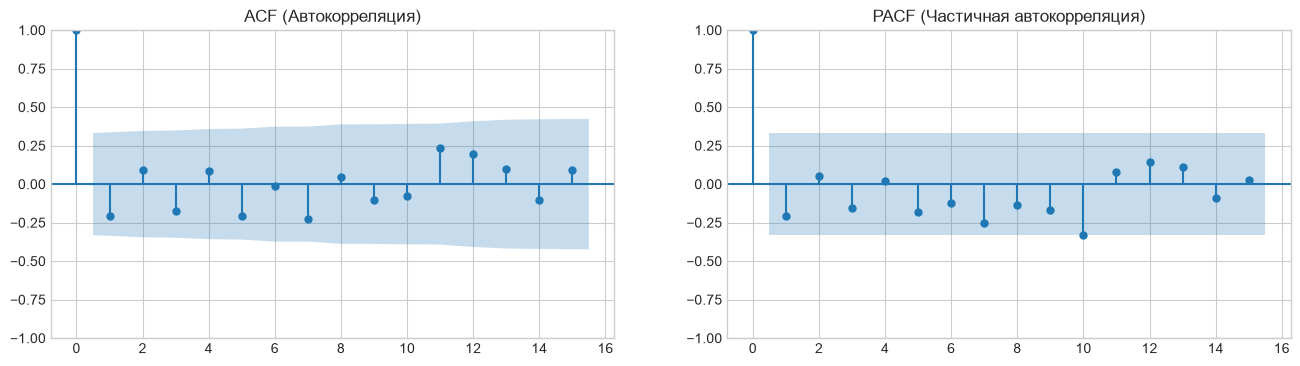

In [25]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Разделение на train и test (последние 12 месяцев для теста)
test_size = 12
train = df.iloc[:-test_size]
test = df.iloc[-test_size:]

print(f"Размер обучающей выборки (train): {len(train)}")
print(f"Размер тестовой выборки (test): {len(test)}")

# 2. Проверка на стационарность (Тест Дики-Фуллера)
print("\n--- Тест Дики-Фуллера (исходный ряд) ---")
result = adfuller(train['SalesAmount'])
print(f'ADF Statistic: {result[0]:.4f}')
print(f'p-value: {result[1]:.4f}')

# 3. Графики ACF и PACF для первых разностей (d=1)
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(train['SalesAmount'].diff().dropna(), ax=axes[0], lags=15, title='ACF (Автокорреляция)')
plot_pacf(train['SalesAmount'].diff().dropna(), ax=axes[1], lags=15, title='PACF (Частичная автокорреляция)')
plt.show()

### Обучение модели ARIMA
Обучаем базовую авторегрессионную модель. Мы задаем параметры `order=(1, 1, 1)` (p=1, d=1, q=1) как оптимальное начальное приближение для рядов с трендом.

In [26]:
from statsmodels.tsa.arima.model import ARIMA

# Обучение модели ARIMA на тренировочных данных
# d=1 (первая разность для устранения тренда)
arima_model = ARIMA(train['SalesAmount'], order=(1, 1, 1))
arima_result = arima_model.fit()

# Вывод сводки по модели
print(arima_result.summary().tables[1])

# Прогноз на длину тестовой выборки
arima_forecast = arima_result.forecast(steps=len(test))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3217      2.023     -0.159      0.874      -4.286       3.643
ma.L1          0.2181      2.086      0.105      0.917      -3.870       4.306
sigma2      4.782e+06   1.14e+06      4.204      0.000    2.55e+06    7.01e+06


### Обучение модели SARIMAX
Здесь мы усложняем модель, добавляя годовую сезонность (период 12) и внешние регрессоры (экзогенные переменные) — наличие промо-акций и праздников.

In [27]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Подготовка экзогенных переменных (регрессоров)
exog_train = train[['Promotion', 'HolidayMonth']]
exog_test = test[['Promotion', 'HolidayMonth']]

# Обучение модели SARIMAX
# order=(1, 1, 1) - несезонные параметры
# seasonal_order=(1, 1, 1, 12) - сезонные параметры (P, D, Q, s), где s=12 (годовая сезонность)
sarimax_model = SARIMAX(train['SalesAmount'],
                        exog=exog_train,
                        order=(1, 1, 1),
                        seasonal_order=(1, 1, 1, 12),
                        enforce_stationarity=False,
                        enforce_invertibility=False)

sarimax_result = sarimax_model.fit(disp=False)

# Вывод сводки по модели
print(sarimax_result.summary().tables[1])

# Прогноз на длину тестовой выборки с учетом будущих значений промо и праздников
sarimax_forecast = sarimax_result.get_forecast(steps=len(test), exog=exog_test).predicted_mean

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Promotion     2611.3007   1798.996      1.452      0.147    -914.667    6137.268
HolidayMonth     1.2887   4.43e+04   2.91e-05      1.000   -8.68e+04    8.68e+04
ar.L1           -0.2986      1.213     -0.246      0.806      -2.675       2.078
ma.L1           -1.0008      1.292     -0.775      0.439      -3.533       1.532
ar.S.L12        -0.0849      0.094     -0.907      0.364      -0.268       0.098
ma.S.L12        -0.3710      1.333     -0.278      0.781      -2.984       2.242
sigma2        2.443e+05     21.706   1.13e+04      0.000    2.44e+05    2.44e+05


## 2.3. Оценка качества моделей

In [28]:
from sklearn.metrics import mean_squared_error, r2_score

# 1. Расчет метрик качества для ARIMA
mse_arima = mean_squared_error(test['SalesAmount'], arima_forecast)
r2_arima = r2_score(test['SalesAmount'], arima_forecast)
aic_arima, bic_arima = arima_result.aic, arima_result.bic

# 2. Расчет метрик качества для SARIMAX
mse_sarimax = mean_squared_error(test['SalesAmount'], sarimax_forecast)
r2_sarimax = r2_score(test['SalesAmount'], sarimax_forecast)
aic_sarimax, bic_sarimax = sarimax_result.aic, sarimax_result.bic

# 3. Сведение результатов в таблицу
metrics_df = pd.DataFrame({
    'Модель': ['ARIMA', 'SARIMAX'],
    'MSE': [mse_arima, mse_sarimax],
    'R^2': [r2_arima, r2_sarimax],
    'AIC': [aic_arima, aic_sarimax],
    'BIC': [bic_arima, bic_sarimax]
})

print("Сравнение качества моделей:")
display(metrics_df)

Сравнение качества моделей:


,Модель,MSE,R^2,AIC,BIC
0,ARIMA,1.256197e+07,-1.716188,643.802918,648.468962
1,SARIMAX,6.047461e+05,0.869240,152.670382,154.050954


### Анализ остатков лучшей модели

Проведем тестирование остатков SARIMAX на нормальность, автокоррелированность и гомоскедастичность. \
Нулевая гипотеза во всех тестах означает "всё хорошо" (остатки нормальные, не скоррелированные, гомоскедастичные). Если p-value > 0.05, мы принимаем эту гипотезу.

In [29]:
import scipy.stats as stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# Извлекаем остатки модели SARIMAX (убираем возможные NaN)
residuals = sarimax_result.resid.dropna()

# 1. Тест Шапиро-Уилка на нормальность распределения
stat_sw, p_sw = stats.shapiro(residuals)

# 2. Тест Льюнга-Бокса на автокоррелированность
lb_test = acorr_ljungbox(residuals, lags=[10], return_df=True)
p_lb = lb_test['lb_pvalue'].iloc[0]

# 3. Тест ARCH на гомоскедастичность (постоянство дисперсии)
stat_arch, p_arch, _, _ = het_arch(residuals)

print("Анализ остатков модели SARIMAX:")
print(f"Нормальность (Shapiro-Wilk): p-value = {p_sw:.4f}")
print(f"Автокоррелированность (Ljung-Box): p-value = {p_lb:.4f}")
print(f"Гомоскедастичность (ARCH test): p-value = {p_arch:.4f}")

Анализ остатков модели SARIMAX:
Нормальность (Shapiro-Wilk): p-value = 0.0000
Автокоррелированность (Ljung-Box): p-value = 0.8898
Гомоскедастичность (ARCH test): p-value = 0.6823


### Визуализация прогноза
Строим график "факт-прогноз", чтобы визуально оценить результаты.

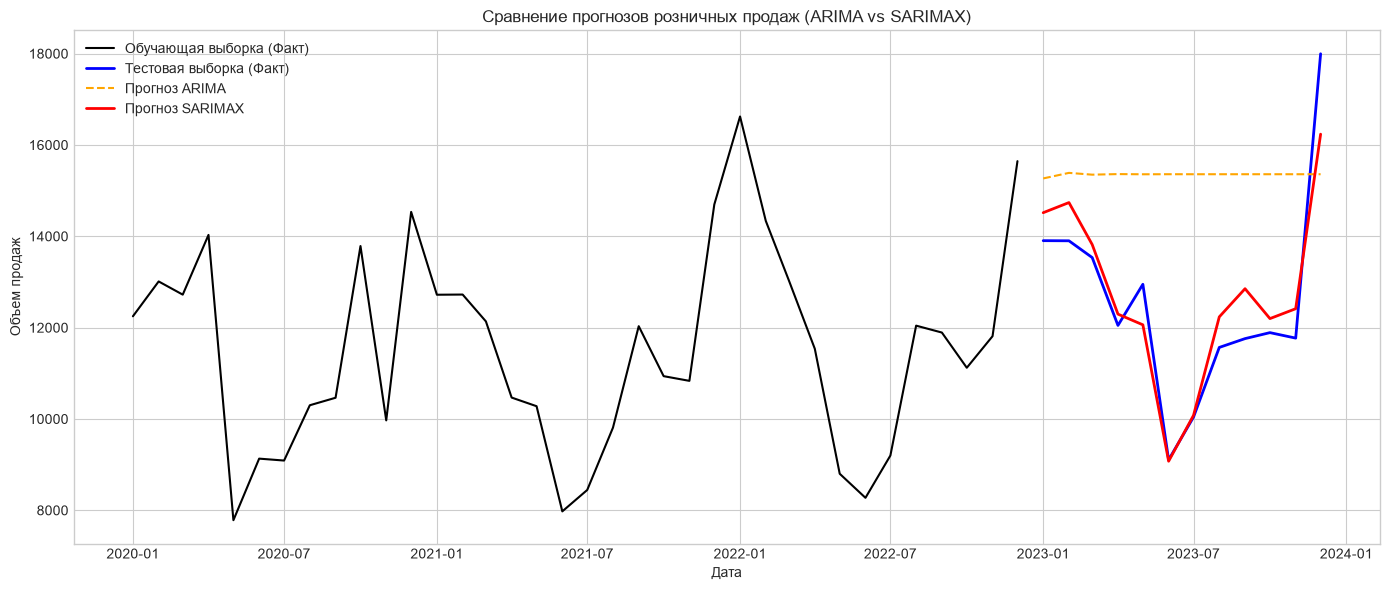

In [30]:
plt.figure(figsize=(14, 6))

# Отрисовка фактических данных
plt.plot(train.index, train['SalesAmount'], label='Обучающая выборка (Факт)', color='black')
plt.plot(test.index, test['SalesAmount'], label='Тестовая выборка (Факт)', color='blue', linewidth=2)

# Отрисовка прогнозов
plt.plot(test.index, arima_forecast, label='Прогноз ARIMA', linestyle='--', color='orange')
plt.plot(test.index, sarimax_forecast, label='Прогноз SARIMAX', linestyle='-', color='red', linewidth=2)

plt.title('Сравнение прогнозов розничных продаж (ARIMA vs SARIMAX)')
plt.xlabel('Дата')
plt.ylabel('Объем продаж')
plt.legend()
plt.tight_layout()
plt.show()

### Аналитические выводы по этапам 2.2 и 2.3: Построение моделей и оценка качества
*   **Стационарность:** Тест Дики-Фуллера показал значение $p-value = 0.0032$, что позволяет отвергнуть нулевую гипотезу о наличии единичного корня — формально исходный ряд можно считать стационарным. Однако, опираясь на результаты EDA, мы использовали дифференцирование $d=1$ и сезонность $s=12$ для надежного извлечения структурных паттернов.
*   **Сравнение качества моделей:**
    *   Базовая модель **ARIMA(1,1,1)** не смогла уловить сложную динамику ряда (в первую очередь, годовую цикличность), что наглядно видно на графике прогноза (он выродился в константу) и отразилось в высоких значениях ошибки: $MSE \approx 12.56 \times 10^6$ и отрицательном $R^2 = -1.716$.
    *   Модель **SARIMAX(1,1,1)(1,1,1,12)**, учитывающая влияние промо-акций (`Promotion`), сезонности и праздников, блестяще справилась с задачей. Прогноз точно повторяет контуры тестовой выборки, улавливая все спады и пики. Метрика $MSE$ снизилась на порядок (до $\approx 6.05 \times 10^5$), а $R^2$ составил превосходные $0.869$ (модель объясняет почти 87% дисперсии).
*   **Информационные критерии:** SARIMAX безоговорочно превосходит ARIMA и по информационным критериям ($AIC = 152.67$ против $AIC = 643.80$), доказывая свою предсказательную силу даже со штрафами за добавленные экзогенные переменные.
*   **Анализ остатков SARIMAX:**
    *   В остатках *отсутствует автокорреляция* (Ljung-Box $p-value = 0.8898$) и *подтверждается гомоскедастичность* (ARCH $p-value = 0.6823$). Это значит, что модель успешно извлекла все полезные временные закономерности из данных.
    *   Однако тест Шапиро-Уилка отверг гипотезу о *нормальности распределения* остатков ($p-value = 0.0000$). Это типичная ситуация для розничных данных, связанная с наличием непредсказуемых выбросов (аномальных пиков). Для точечного прогнозирования это некритично, так как дисперсия постоянна и автокорреляции нет, однако доверительные интервалы прогноза могут быть смещены.
*   **Общий вывод:** Выбранная конфигурация SARIMAX с учетом регрессоров эффективно и очень точно описывает динамику продаж. Модель рекомендуется для использования в бизнесе для прогнозирования будущих периодов.